<a href="https://colab.research.google.com/github/cras-lab/GenAI/blob/main/%EC%83%9D%EC%84%B1%EB%AA%A8%EB%8D%B8_ToyExample.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

학습 데이터 개수: 2006
Epoch    0 | NLL = 3.0064
Epoch  200 | NLL = 2.0804
Epoch  400 | NLL = 2.0727
Epoch  600 | NLL = 2.0707
Epoch  800 | NLL = 2.0698
Epoch 1000 | NLL = 2.0692


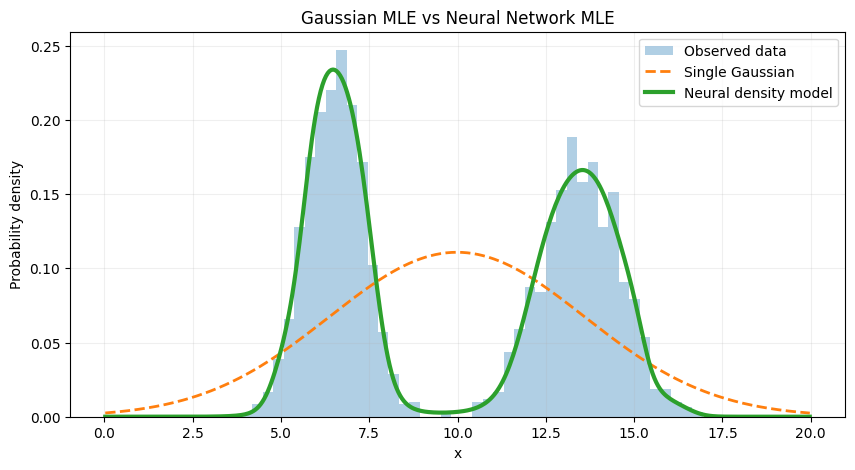

새로 생성한 숫자 12개:
[12.58  6.88 12.49  5.05  5.54 13.51 12.77 13.91  7.14 12.43  6.59  7.01]


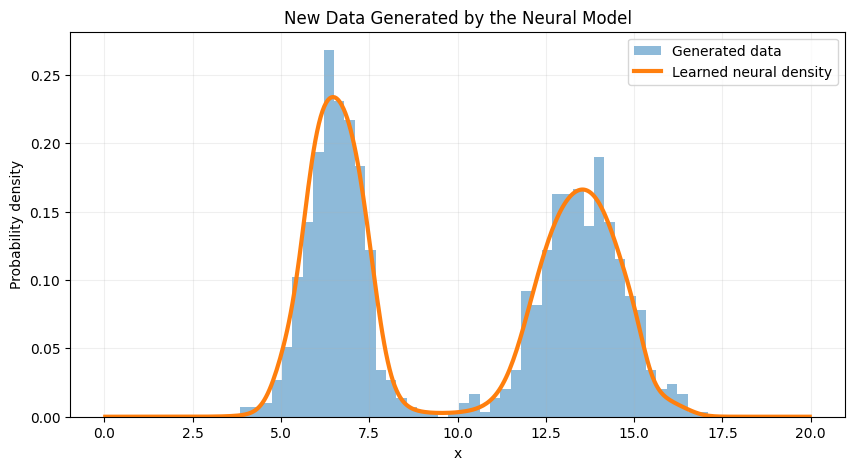

In [1]:

import math
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

# STEP 1. 관측 데이터 준비
# 기존 6개 숫자
original = torch.tensor(
    [5.2, 7.1, 8.8, 11.4, 12.7, 15.3]
)

# 실습용 가상 모집단에서 2,000개 추가 관측
# 아래 생성 규칙은 신경망에 알려주지 않음
n = 2000
group = torch.rand(n) < 0.5

extra = torch.where(
    group,
    6.5 + 0.8 * torch.randn(n),
    13.5 + 1.1 * torch.randn(n)
)

data = torch.cat([original, extra]).clamp(0, 20)

print("학습 데이터 개수:", len(data))


# STEP 2. 신경망 모델 정의
# 입력 x -> 신경망 -> 밀도 계산용 점수
net = nn.Sequential(
    nn.Linear(1, 32),
    nn.Tanh(),
    nn.Linear(32, 32),
    nn.Tanh(),
    nn.Linear(32, 1)
)

def score(x):
    x = (x.reshape(-1, 1) - 10) / 10
    return net(x).squeeze(-1)


# STEP 3. 최대우도추정(MLE)으로 학습
# 확률밀도를 정규화할 구간 [0, 20]
dx = 20 / 400
grid = torch.linspace(dx/2, 20-dx/2, 400)

optimizer = torch.optim.Adam(net.parameters(), lr=0.01)

for epoch in range(1001):
    # log Z = log integral exp(f(x)) dx
    log_Z = torch.logsumexp(score(grid), dim=0) + math.log(dx)

    # Negative log-likelihood
    loss = log_Z - score(data).mean()

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if epoch % 200 == 0:
        print(f"Epoch {epoch:4d} | NLL = {loss.item():.4f}")


# STEP 4. 학습된 확률밀도 계산
with torch.no_grad():
    log_Z = torch.logsumexp(score(grid), dim=0) + math.log(dx)
    density = torch.exp(score(grid) - log_Z).numpy()

x_axis = grid.numpy()
observed = data.numpy()

# 비교용: 단일 정규분포 MLE
mu = observed.mean()
sigma = observed.std(ddof=0)

normal_pdf = (
    np.exp(-0.5 * ((x_axis - mu) / sigma)**2)
    / (sigma * np.sqrt(2*np.pi))
)

# 동일한 [0,20] 구간에서 정규화
normal_pdf /= normal_pdf.sum() * dx

# STEP 5. 관측 데이터와 두 모델 비교
plt.figure(figsize=(10, 5))
plt.hist(observed, bins=45, density=True,
         alpha=0.35, label="Observed data")
plt.plot(x_axis, normal_pdf, "--", linewidth=2,
         label="Single Gaussian")
plt.plot(x_axis, density, linewidth=3,
         label="Neural density model")
plt.xlabel("x")
plt.ylabel("Probability density")
plt.title("Gaussian MLE vs Neural Network MLE")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


# STEP 6. 학습한 분포에서 새로운 숫자 생성
with torch.no_grad():
    probabilities = torch.tensor(density * dx)
    indices = torch.multinomial(
        probabilities, 1000, replacement=True
    )
    generated = (
        grid[indices] +
        (torch.rand(1000) - 0.5) * dx
    ).numpy()

print("새로 생성한 숫자 12개:")
print(np.round(generated[:12], 2))

plt.figure(figsize=(10, 5))
plt.hist(generated, bins=45, density=True,
         alpha=0.5, label="Generated data")
plt.plot(x_axis, density, linewidth=3,
         label="Learned neural density")
plt.xlabel("x")
plt.ylabel("Probability density")
plt.title("New Data Generated by the Neural Model")
plt.legend()
plt.grid(alpha=0.2)
plt.show()
